In [1]:
# Humedad relativa del aire - Barranquilla (parte 2)
# en el notebook 01 el arbol usaba la humedad para predecir la clase, y eso da 100% porque
# la clase sale de la misma humedad. aqui el arbol predice la clase con la hora y el mes,
# que salen de la columna FechaObservacion del mismo archivo
# datos de datos.gov.co (IDEAM): Humedad del Aire

import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# busco donde esta el csv: misma carpeta, ../data o /content (colab)
carpeta = "."
for c in [".", "../data", "/content"]:
    if os.path.exists(c + "/Humedad_del_Aire_20261028.csv"):
        carpeta = c
        break
archivo = carpeta + "/Humedad_del_Aire_20261028.csv"

In [2]:
# Limpieza (igual que en el notebook 01)
df = pd.read_csv(archivo)
print(df.shape)

# el archivo trae humedad del suelo tambien, solo dejo la del aire
df = df[df["DescripcionSensor"] == "Humedad del aire 2 mt"].reset_index(drop=True)
# barranquilla viene escrito de 2 formas
df["Municipio"] = df["Municipio"].str.upper()
df = df.drop_duplicates().reset_index(drop=True)
# humedad en 0 no tiene sentido, es error del sensor
df = df[df["ValorObservado"] > 0].reset_index(drop=True)

df["FechaObservacion"] = pd.to_datetime(df["FechaObservacion"], format="%Y %b %d %I:%M:%S %p", errors="coerce")
df["ANIO"] = df["FechaObservacion"].dt.year
df["NUM_MES"] = df["FechaObservacion"].dt.month
df = df.dropna(subset=["FechaObservacion"]).reset_index(drop=True)

df = df[["FechaObservacion", "ANIO", "NUM_MES", "NombreEstacion", "Municipio", "ValorObservado"]]
df = df.rename(columns={"ValorObservado": "HUMEDAD"})

# la hora tambien sale de la fecha
df["HORA"] = df["FechaObservacion"].dt.hour
print(df.shape)
print(df["HUMEDAD"].describe())

# guardo todos los datos limpios para sacar los promedios reales por mes y hora
df_completo = df.copy()

(119575, 12)


(82594, 7)
count    82594.000000
mean        84.711492
std          9.653961
min          2.000000
25%         78.000000
50%         85.000000
75%         91.000000
max        100.000000
Name: HUMEDAD, dtype: float64


In [3]:
# saco 10000 datos
df = df.sample(n=10000, random_state=42).sort_values("FechaObservacion").reset_index(drop=True)

# menos de 75 baja, de 75 a 88 media, mas de 88 alta
clase = []
for h in df["HUMEDAD"]:
    if h < 75:
        clase.append("Baja")
    elif h < 88:
        clase.append("Media")
    else:
        clase.append("Alta")
df["CLASE"] = clase
print(df["CLASE"].value_counts())

CLASE
Media    4654
Alta     3836
Baja     1510
Name: count, dtype: int64


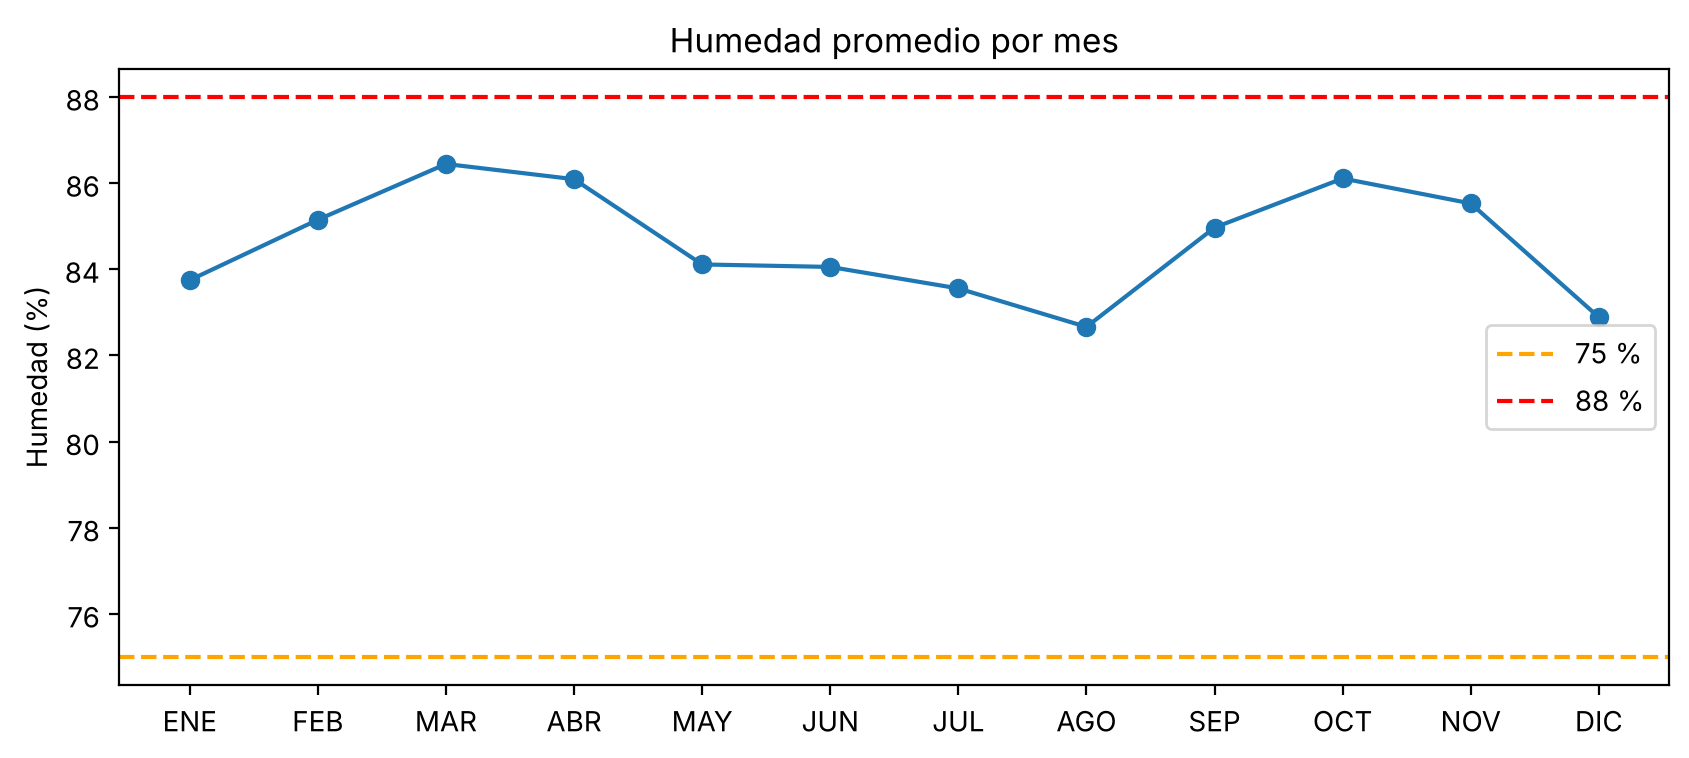

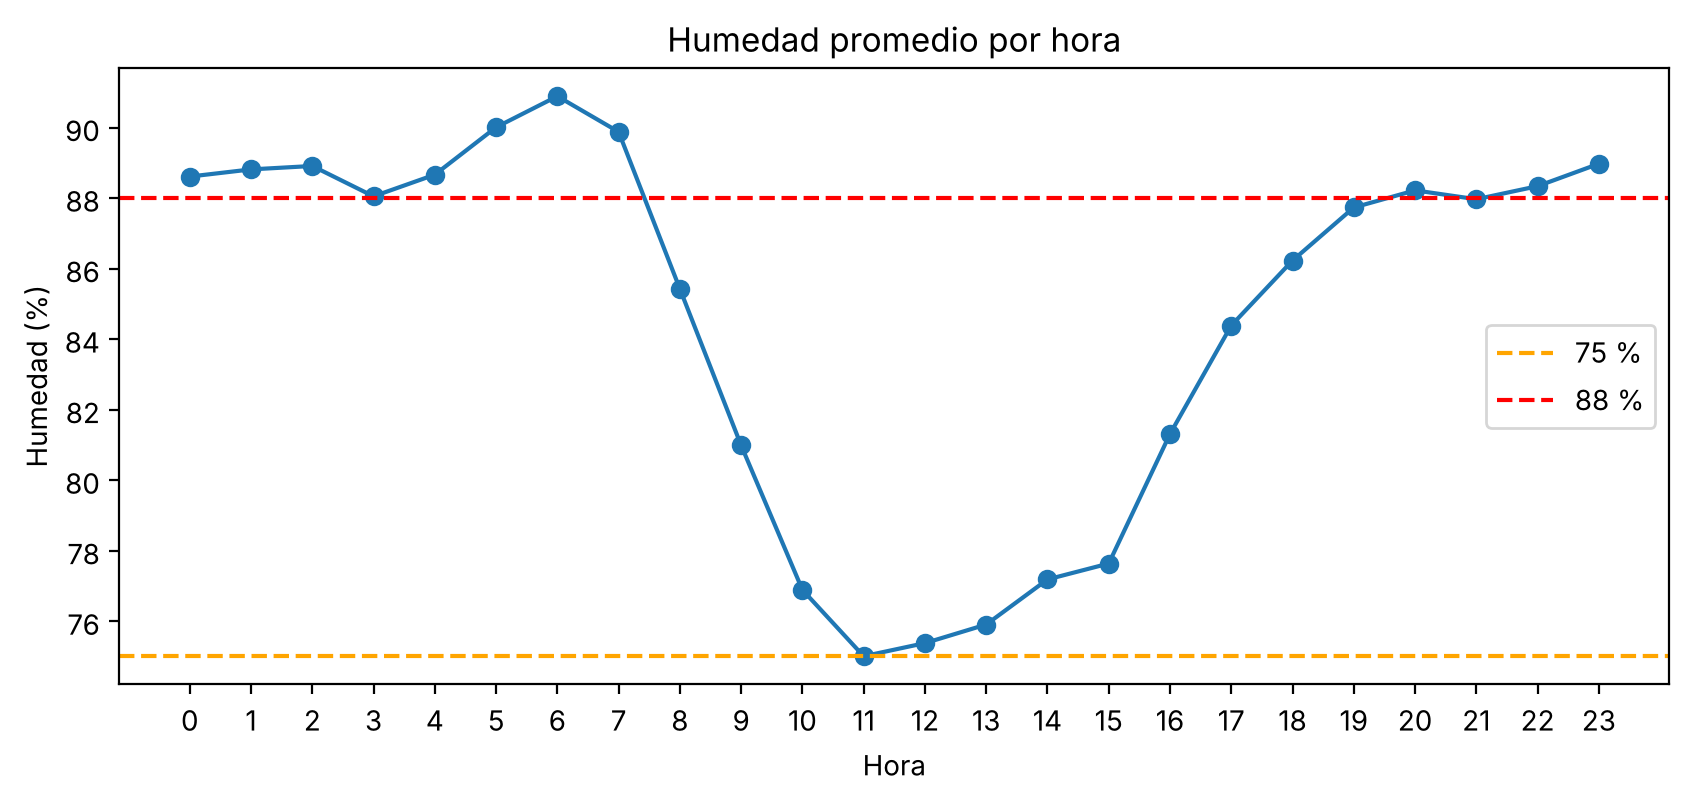

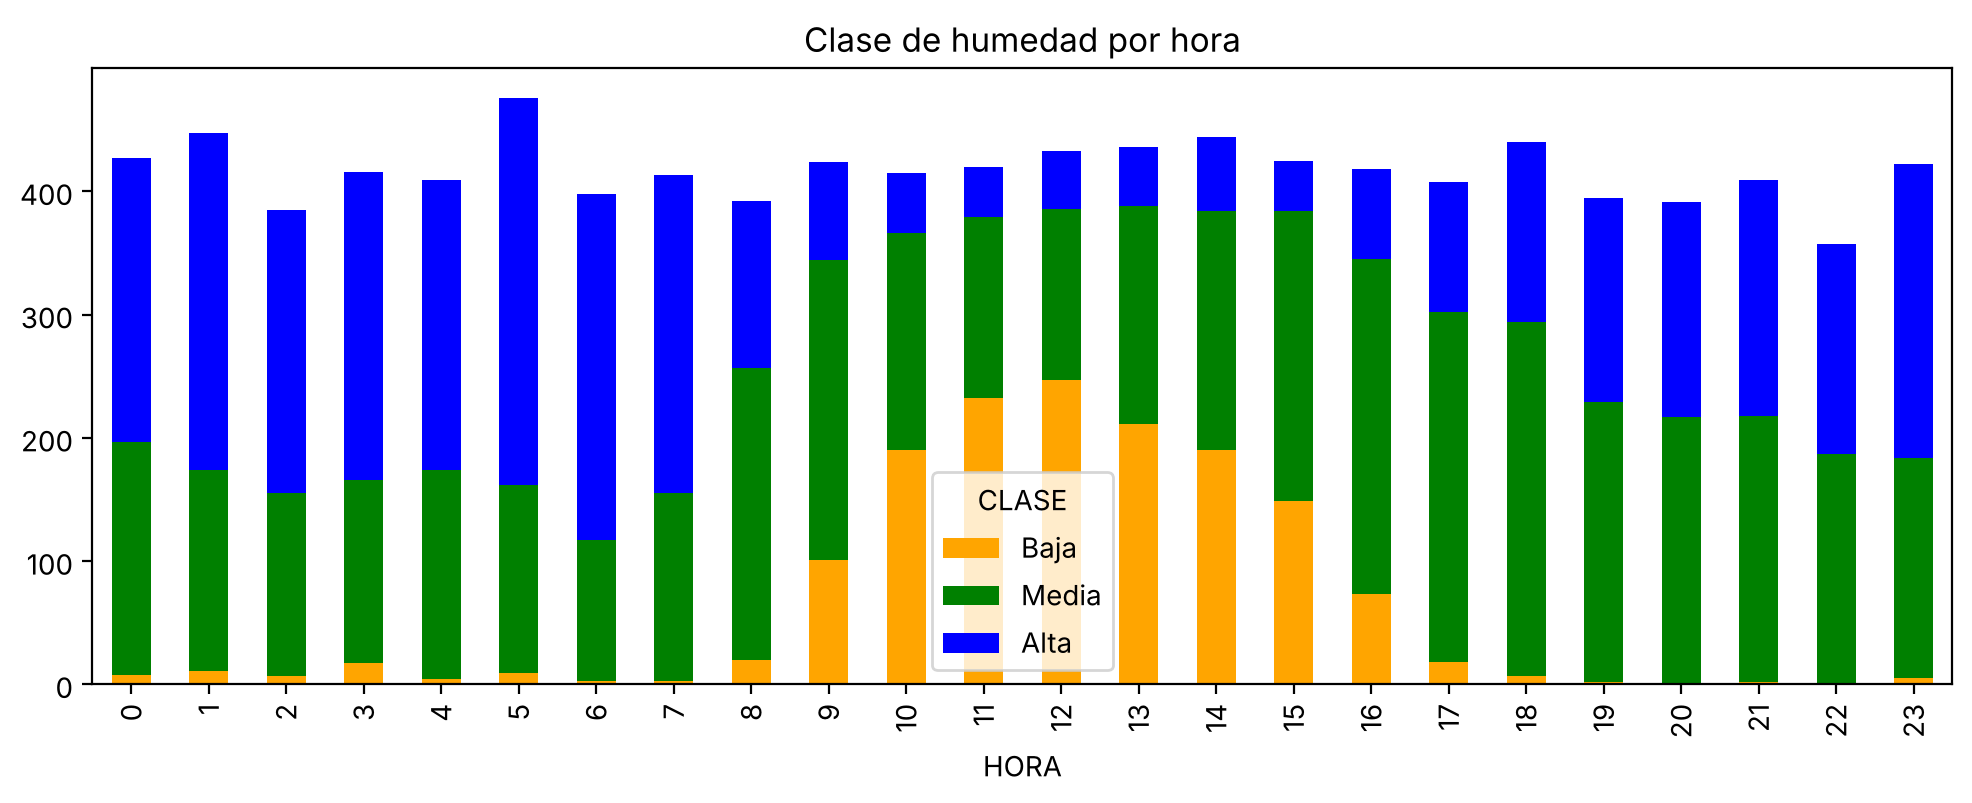

In [4]:
meses = ["ENE","FEB","MAR","ABR","MAY","JUN","JUL","AGO","SEP","OCT","NOV","DIC"]

promedio_mes = df.groupby("NUM_MES")["HUMEDAD"].mean()
plt.figure(figsize=(10,4))
plt.plot(promedio_mes.index, promedio_mes.values, marker="o")
plt.axhline(75, color="orange", linestyle="--", label="75 %")
plt.axhline(88, color="red", linestyle="--", label="88 %")
plt.xticks(range(1,13), meses)
plt.ylabel("Humedad (%)")
plt.title("Humedad promedio por mes")
plt.legend()
plt.show()

promedio_hora = df.groupby("HORA")["HUMEDAD"].mean()
plt.figure(figsize=(10,4))
plt.plot(promedio_hora.index, promedio_hora.values, marker="o")
plt.axhline(75, color="orange", linestyle="--", label="75 %")
plt.axhline(88, color="red", linestyle="--", label="88 %")
plt.xticks(range(0,24))
plt.xlabel("Hora")
plt.ylabel("Humedad (%)")
plt.title("Humedad promedio por hora")
plt.legend()
plt.show()

# clase por hora
pd.crosstab(df["HORA"], df["CLASE"])[["Baja", "Media", "Alta"]].plot(kind="bar", stacked=True, figsize=(12,4), color=["orange", "green", "blue"])
plt.title("Clase de humedad por hora")
plt.show()

In [5]:
# el arbol del notebook 01 usaba la humedad para predecir la clase
X = df[["HUMEDAD"]]
y = df["CLASE"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
arbol_original = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol_original.fit(X_train, y_train)
print("Precisión arbol original:", accuracy_score(y_test, arbol_original.predict(X_test)))
# da 1.0 porque la clase sale de la misma humedad, entonces no predice nada nuevo

Precisión arbol original: 1.0


In [6]:
# ahora con la hora y el mes (sin la humedad)
FEATURES = ["HORA", "NUM_MES"]
X = df[FEATURES]
y = df["CLASE"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# para comparar: si siempre digo la clase que mas sale
base = y_train.value_counts().idxmax()
print("Siempre", base, ":", accuracy_score(y_test, [base] * len(y_test)))

# pruebo varias profundidades
for p in [3, 4, 5, 6, 8]:
    a = DecisionTreeClassifier(max_depth=p, random_state=42)
    a.fit(X_train, y_train)
    print("max_depth", p, "precisión", round(accuracy_score(y_test, a.predict(X_test)), 3), "hojas", a.get_n_leaves())

Siempre Media : 0.4652
max_depth 3 precisión 0.569 hojas 8
max_depth 4 precisión 0.581 hojas 16
max_depth 5 precisión 0.597 hojas 31
max_depth 6 precisión 0.598 hojas 55
max_depth 8 precisión 0.601 hojas 147


Precisión: 0.5812
{'HORA': np.float64(0.924760329952074), 'NUM_MES': np.float64(0.07523967004792595)}


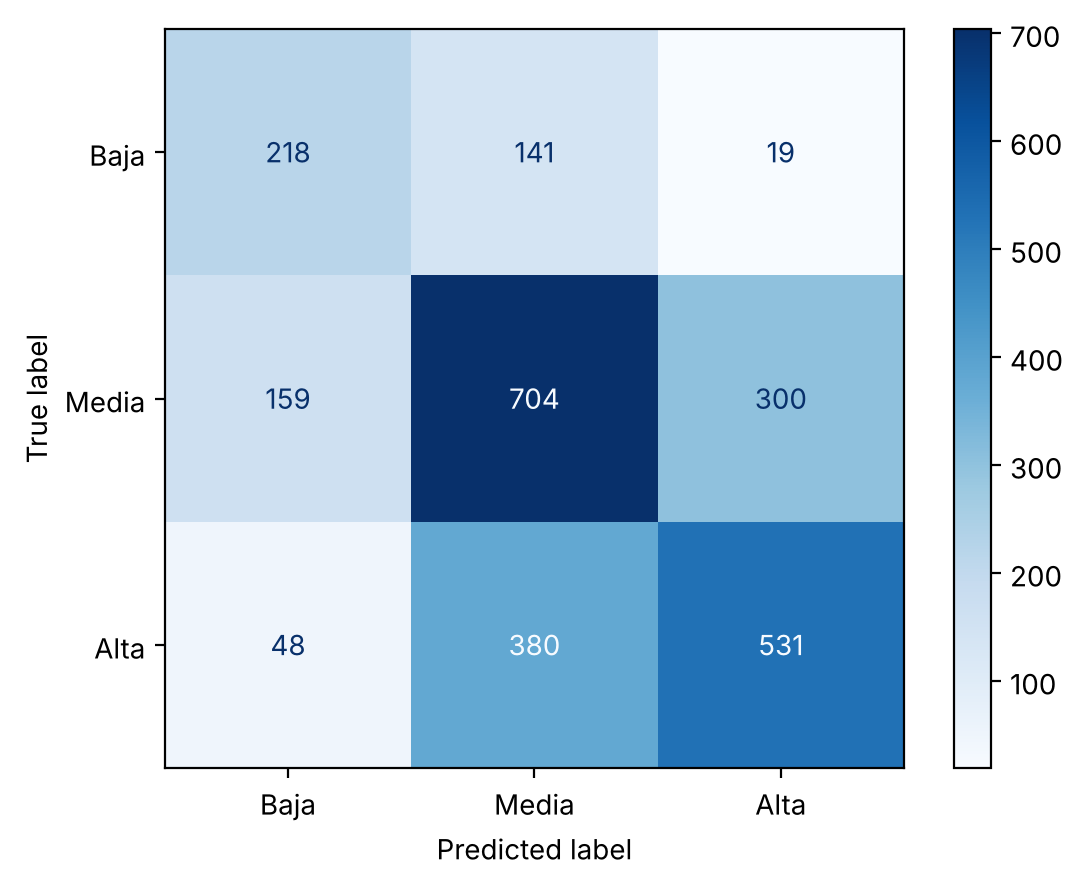

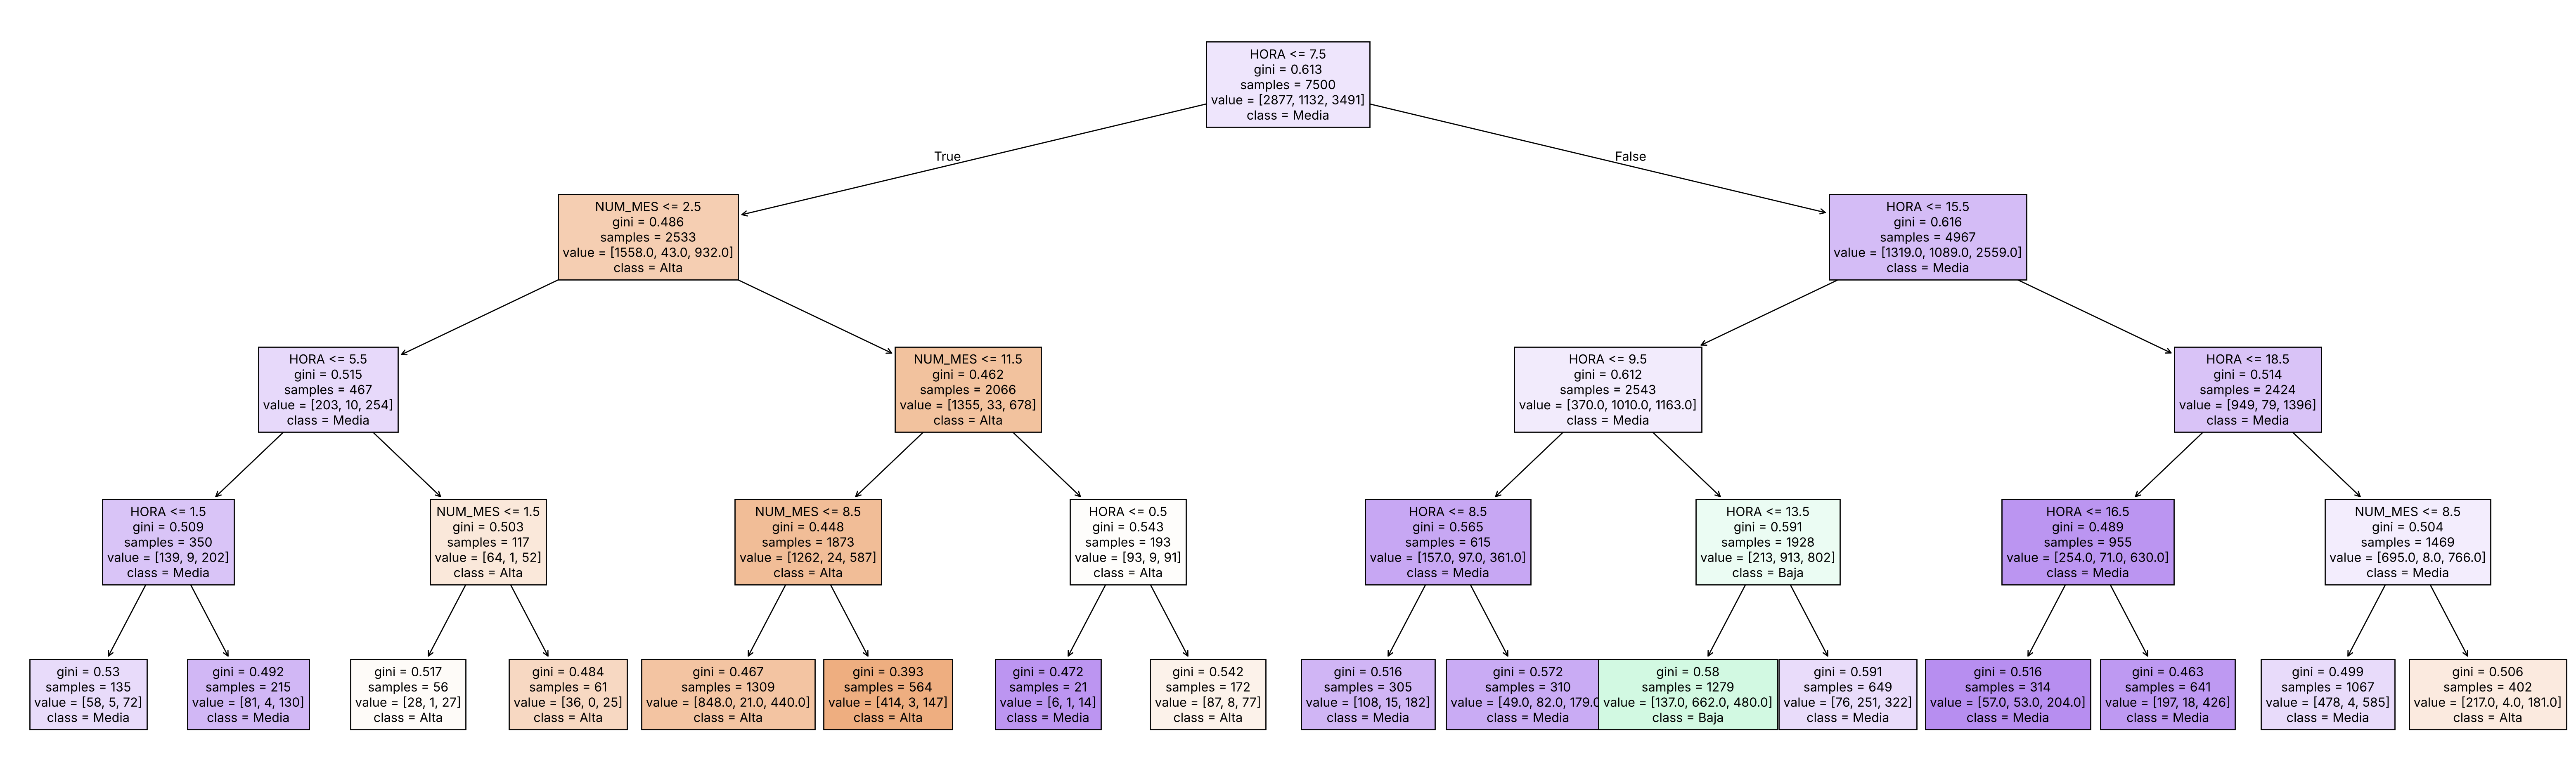

In [7]:
# me quedo con max_depth=4: con mas profundidad mejora muy poco y el arbol se puede ver completo
arbol = DecisionTreeClassifier(max_depth=4, random_state=42)
arbol.fit(X_train, y_train)

y_pred = arbol.predict(X_test)
print("Precisión:", accuracy_score(y_test, y_pred))
print(dict(zip(FEATURES, arbol.feature_importances_)))

orden = ["Baja", "Media", "Alta"]
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=orden), display_labels=orden).plot(cmap="Blues")
plt.show()

plt.figure(figsize=(40,12))
plot_tree(arbol, feature_names=FEATURES, class_names=arbol.classes_, filled=True, fontsize=11)
# guardo la imagen del arbol para la pagina
plt.savefig("../web/arbol.png" if os.path.exists("../web") else "arbol.png", dpi=80, bbox_inches="tight")
plt.show()

In [8]:
# Predicción
casos = pd.DataFrame({
    "HORA": [4, 13, 21],
    "NUM_MES": [10, 2, 5],
})
print(casos)
print(arbol.predict(casos))
print(arbol.classes_)
print(arbol.predict_proba(casos))

   HORA  NUM_MES
0     4       10
1    13        2
2    21        5
['Alta' 'Baja' 'Media']
['Alta' 'Baja' 'Media']
[[0.73404255 0.00531915 0.2606383 ]
 [0.10711493 0.51759187 0.3752932 ]
 [0.447985   0.00374883 0.54826617]]


## Conclusiones

- El arbol del notebook 01 da 100 %, pero no sirve para predecir porque usa la misma humedad con la que se saca la clase.
- Con la hora y el mes el arbol acierta el 58,1 % de los datos de prueba (2.500 mediciones que no vio al entrenar). Si siempre dijeramos "Media" acertariamos el 46,5 %, entonces el arbol si aprende algo.
- La hora es lo que mas pesa (93 %): la humedad baja entre las 9 a. m. y las 2 p. m. y sube en la noche y la madrugada.
- El mes pesa poco (8 %). Sobre todo separa enero a marzo, que es la temporada seca.
- Cuando se equivoca casi siempre es entre clases vecinas (Media con Alta o Media con Baja). Casi nunca confunde Baja con Alta.
- Con mas profundidad (max_depth=6 u 8) mejora muy poco (60 %), por eso dejamos max_depth=4, que se puede ver completo.

In [9]:
# exporto el arbol a web/model.js para la pagina
t = arbol.tree_
# humedad promedio de los datos de entrenamiento que caen en cada hoja
hojas_train = arbol.apply(X_train)
hum_hoja = pd.Series(df.loc[X_train.index, "HUMEDAD"].values).groupby(hojas_train).mean()

def nodo(i):
    p = t.value[i][0] / t.value[i][0].sum()
    n = {"n": int(t.n_node_samples[i]), "p": [round(float(x), 3) for x in p], "g": round(float(t.impurity[i]), 3),
         "v": [int(round(float(x) * t.n_node_samples[i])) for x in p]}  # cuantos hay de cada clase
    if t.children_left[i] != -1:
        n["f"] = FEATURES[t.feature[i]]
        n["t"] = round(float(t.threshold[i]), 2)
        n["l"] = nodo(t.children_left[i])
        n["r"] = nodo(t.children_right[i])
    else:
        n["h"] = round(float(hum_hoja[i]), 1)
    return n

# por cada mes y hora saco el promedio real, cuantos datos hay y el % de baja, media y alta
# (con todos los datos limpios, no solo la muestra de 10000)
reales = []
for m in range(1, 13):
    fila = []
    for h in range(24):
        d = df_completo[(df_completo["NUM_MES"] == m) & (df_completo["HORA"] == h)]["HUMEDAD"]
        fila.append([round(float(d.mean()), 1), int(len(d)),
                     round(float((d < 75).mean() * 100)),
                     round(float(((d >= 75) & (d < 88)).mean() * 100)),
                     round(float((d >= 88).mean() * 100))])
    reales.append(fila)

# por cada dato de prueba guardo la hora, el mes, la clase real y la que dijo el arbol
# (0 = Baja, 1 = Media, 2 = Alta) para armar la matriz de confusion en la pagina
prueba = []
for h, m, real, pred in zip(X_test["HORA"], X_test["NUM_MES"], y_test, y_pred):
    prueba.append([int(h), int(m), orden.index(real), orden.index(pred)])

modelo = {
    "meta": {
        "fuente": "IDEAM vía datos.gov.co: Humedad del Aire (uext-mhny)",
        "estacion": "Escuela Naval Barranquilla",
        "desde": str(df["FechaObservacion"].min().date()),
        "hasta": str(df["FechaObservacion"].max().date()),
        "registros": len(df), "train": len(X_train), "test": len(X_test),
    },
    "clases": list(arbol.classes_),
    "cortes": [75, 88],
    "precision": round(accuracy_score(y_test, y_pred), 3),
    "precision_base": round(accuracy_score(y_test, [base] * len(y_test)), 3),
    "precision_original": round(accuracy_score(y_test, arbol_original.predict(df.loc[X_test.index, ["HUMEDAD"]])), 3),
    "matriz": confusion_matrix(y_test, y_pred, labels=orden).tolist(),
    "orden": orden,
    "importancias": {f: round(float(v), 3) for f, v in zip(FEATURES, arbol.feature_importances_)},
    "profundidad": int(arbol.get_depth()),
    "hojas": int(arbol.get_n_leaves()),
    "arbol": nodo(0),
    "promedio_hora": [round(float(x), 1) for x in df.groupby("HORA")["HUMEDAD"].mean()],
    "reales": reales,
    "prueba": prueba,
}

salida = "../web/model.js" if os.path.exists("../web") else "model.js"
with open(salida, "w", encoding="utf-8") as f:
    f.write("window.MODEL=" + json.dumps(modelo, ensure_ascii=False) + ";\n")
print("guardado en", salida)

guardado en ../web/model.js
